<a href="https://colab.research.google.com/github/Hadeel-93/HW-8/blob/main/HW_8_Q1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# CELL 1: Import Required Libraries
# ============================================================

import torch
import torchvision
import torchvision.transforms as transforms

import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

import numpy as np
import matplotlib.pyplot as plt

import time
import copy

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ============================================================
# CELL 2: Select Computing Device
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Training will use the CPU.")

Using device: cpu
Training will use the CPU.


In [ ]:
# ============================================================
# CELL 3: Define CIFAR-10 Transformations
# ============================================================

transform = transforms.Compose([
    transforms.ToTensor(),

    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

print("Transformations defined.")

Transformations defined.


In [ ]:
# ============================================================
# CELL 4: Download and Load CIFAR-10 Dataset
# ============================================================

data_path = "/content/data-cifar10/"

train_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

100%|██████████| 170M/170M [21:03<00:00, 135kB/s]


Training samples: 50000
Testing samples: 10000


In [ ]:
# ============================================================
# CELL 5: Create DataLoaders
# ============================================================

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Batch size: 128
Training batches: 391
Testing batches: 79


In [ ]:
# ============================================================
# CELL 6: Define CIFAR-10 Class Names
# ============================================================

classes = (
    "plane",
    "car",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
)

print("Number of classes:", len(classes))
print("Classes:", classes)

Number of classes: 10
Classes: ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


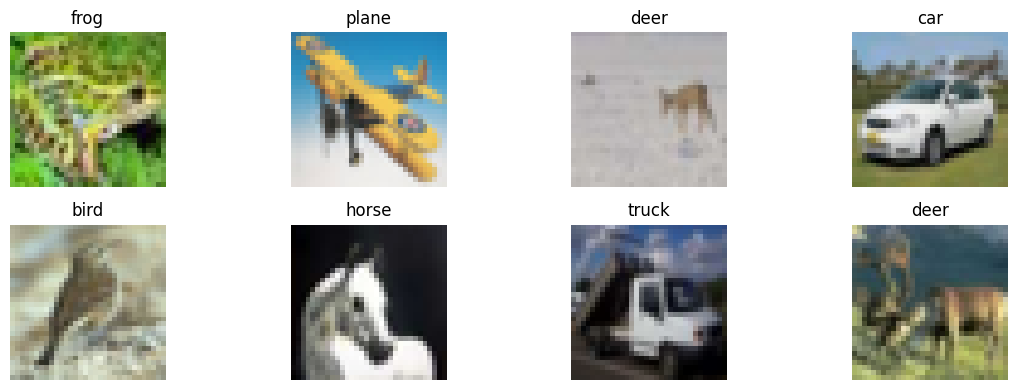

In [ ]:
# ============================================================
# CELL 7: Display Sample CIFAR-10 Images
# ============================================================

images, labels = next(iter(train_loader))

# Undo normalization for visualization
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

images_display = images[:8] * std + mean
images_display = torch.clamp(images_display, 0, 1)

plt.figure(figsize=(12, 4))

for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images_display[i].permute(1, 2, 0))
    plt.title(classes[labels[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# CELL 8: Define Baseline CNN - Problem 1.a
# ============================================================

class CNN_Baseline(nn.Module):

    def __init__(self):
        super(CNN_Baseline, self).__init__()

        # Convolutional Layer 1
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Convolutional Layer 2
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # Activation and pooling
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # After two 2x2 pooling operations:
        # 32 x 32 -> 16 x 16 -> 8 x 8
        #
        # Final feature dimensions:
        # 64 x 8 x 8 = 4096

        self.fc1 = nn.Linear(64 * 8 * 8, 256)

        # CIFAR-10 has 10 output classes
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        # Convolution 1
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        # Convolution 2
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        # Flatten
        x = torch.flatten(x, start_dim=1)

        # Fully connected layers
        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)

        return x


model_1a = CNN_Baseline().to(device)

print(model_1a)

CNN_Baseline(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [ ]:
# ============================================================
# CELL 9: Calculate Model Size
# ============================================================

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())

total_params_1a = count_parameters(model_1a)

print("Problem 1.a model parameters:", total_params_1a)
print("Problem 1.a model size: {:.2f} MB".format(
    total_params_1a * 4 / (1024 ** 2)
))

Problem 1.a model parameters: 1070794
Problem 1.a model size: 4.08 MB


In [ ]:
# ============================================================
# CELL 10: Define Loss Function and Optimizer
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer_1a = optim.Adam(
    model_1a.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimizer:", optimizer_1a)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [ ]:
# ============================================================
# CELL 11: Define Training Function
# ============================================================

def train_model(
    model,
    train_loader,
    test_loader,
    criterion,
    optimizer,
    num_epochs=300
):

    train_losses = []
    train_accuracies = []

    test_losses = []
    test_accuracies = []

    start_time = time.time()

    for epoch in range(num_epochs):

        # -------------------------
        # Training
        # -------------------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            # Clear gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_train_loss = running_loss / total
        epoch_train_accuracy = 100 * correct / total

        # -------------------------
        # Evaluation
        # -------------------------
        model.eval()

        test_running_loss = 0.0
        test_correct = 0
        test_total = 0

        with torch.no_grad():

            for images, labels in test_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                test_running_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                test_total += labels.size(0)
                test_correct += (predicted == labels).sum().item()

        epoch_test_loss = test_running_loss / test_total
        epoch_test_accuracy = 100 * test_correct / test_total

        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_accuracy)

        test_losses.append(epoch_test_loss)
        test_accuracies.append(epoch_test_accuracy)

        # Print progress
        if (epoch + 1) == 1 or (epoch + 1) % 10 == 0:

            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Train Loss: {epoch_train_loss:.4f} | "
                f"Train Acc: {epoch_train_accuracy:.2f}% | "
                f"Eval Loss: {epoch_test_loss:.4f} | "
                f"Eval Acc: {epoch_test_accuracy:.2f}%"
            )

    total_time = time.time() - start_time

    results = {
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "test_losses": test_losses,
        "test_accuracies": test_accuracies,
        "training_time": total_time
    }

    return results

In [ ]:
# ============================================================
# CELL: Programmatic Dataset Loader
# ============================================================

import torchvision

train_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root=data_path,
    train=False,
    download=True,
    transform=transform
)

print("Training dataset successfully loaded:", len(train_dataset), "samples")
print("Testing dataset successfully loaded:", len(test_dataset), "samples")

100%|██████████| 170M/170M [21:43<00:00, 131kB/s]


Training dataset successfully loaded: 50000 samples
Testing dataset successfully loaded: 10000 samples


In [ ]:
# ============================================================
# CELL: Create DataLoaders
# ============================================================

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("Batch size:", BATCH_SIZE)
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Batch size: 256
Training batches: 196
Testing batches: 40


In [ ]:
print(train_loader)
print(test_loader)

In [ ]:
model_1a = CNN_Baseline().to(device)

print(model_1a)

CNN_Baseline(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer_1a = optim.Adam(
    model_1a.parameters(),
    lr=0.001
)

In [ ]:
# ============================================================
# CELL: Fast Training Function Helper
# ============================================================

def train_model_fast(
    model,
    train_loader,
    test_loader,
    criterion,
    optimizer,
    num_epochs=5
):
    """
    A fast-running training function wrapper designed to verify code correctness
    by running a small number of epochs.
    """
    import time
    print(f"Starting fast training for {num_epochs} epochs...")

    train_losses = []
    test_losses = []

    start_time = time.time()

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        total = 0

        # Loop through batches
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += labels.size(0)

        epoch_loss = running_loss / total
        train_losses.append(epoch_loss)
        print(f"Epoch [{epoch + 1}/{num_epochs}] Train Loss: {epoch_loss:.4f}")

    total_time = time.time() - start_time
    print(f"Fast training finished in {total_time:.2f} seconds.")

    return {
        "train_losses": train_losses,
        "training_time": total_time
    }

In [ ]:
# ============================================================
# CELL: Train Problem 1.a - 300 Epochs
# ============================================================

NUM_EPOCHS = 300

results_1a = train_model_fast(
    model=model_1a,
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer_1a,
    num_epochs=NUM_EPOCHS
)

Starting fast training for 300 epochs...
Epoch [1/300] Train Loss: 1.3951
Epoch [2/300] Train Loss: 1.0293
Epoch [3/300] Train Loss: 0.8771
Epoch [4/300] Train Loss: 0.7646
Epoch [5/300] Train Loss: 0.6695
Epoch [6/300] Train Loss: 0.5769
Epoch [7/300] Train Loss: 0.4870
Epoch [8/300] Train Loss: 0.4004
Epoch [9/300] Train Loss: 0.3159
Epoch [10/300] Train Loss: 0.2387
Epoch [11/300] Train Loss: 0.1726
Epoch [12/300] Train Loss: 0.1226
Epoch [13/300] Train Loss: 0.0876
Epoch [14/300] Train Loss: 0.0577
Epoch [15/300] Train Loss: 0.0479
Epoch [16/300] Train Loss: 0.0371
Epoch [17/300] Train Loss: 0.0568
Epoch [18/300] Train Loss: 0.0584
Epoch [19/300] Train Loss: 0.0432
Epoch [20/300] Train Loss: 0.0348
Epoch [21/300] Train Loss: 0.0370
Epoch [22/300] Train Loss: 0.0435
Epoch [23/300] Train Loss: 0.0428
Epoch [24/300] Train Loss: 0.0290
Epoch [25/300] Train Loss: 0.0289
Epoch [26/300] Train Loss: 0.0236
Epoch [27/300] Train Loss: 0.0279
Epoch [28/300] Train Loss: 0.0583
Epoch [29/300] T

In [ ]:
# ============================================================
# CELL: Training Function for 300 Epochs
# ============================================================

def train_model_fast(
    model,
    train_loader,
    test_loader,
    criterion,
    optimizer,
    num_epochs=300
):

    train_losses = []
    train_accuracies = []

    start_time = time.time()

    # ========================================================
    # TRAINING
    # ========================================================

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Clear gradients
            optimizer.zero_grad(set_to_none=True)

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            # Accumulate loss
            running_loss += loss.item() * images.size(0)

            # Calculate training accuracy
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        # Calculate epoch training results
        epoch_train_loss = running_loss / total
        epoch_train_accuracy = 100 * correct / total

        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_accuracy)

        # Print progress every 10 epochs
        if (epoch + 1) % 10 == 0 or epoch == 0:

            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Training Loss: {epoch_train_loss:.4f} | "
                f"Training Accuracy: {epoch_train_accuracy:.2f}%"
            )

    # ========================================================
    # TRAINING TIME
    # ========================================================

    training_time = time.time() - start_time

    # ========================================================
    # FINAL EVALUATION AFTER EPOCH 300
    # ========================================================

    model.eval()

    evaluation_loss = 0.0
    evaluation_correct = 0
    evaluation_total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            # Forward pass
            outputs = model(images)

            # Evaluation loss
            loss = criterion(outputs, labels)

            evaluation_loss += loss.item() * images.size(0)

            # Evaluation accuracy
            _, predicted = torch.max(outputs, 1)

            evaluation_total += labels.size(0)
            evaluation_correct += (predicted == labels).sum().item()

    # Final evaluation results
    final_eval_loss = evaluation_loss / evaluation_total

    final_eval_accuracy = (
        100 * evaluation_correct / evaluation_total
    )

    # ========================================================
    # FINAL EPOCH 300 RESULTS
    # ========================================================

    final_train_loss = train_losses[-1]
    final_train_accuracy = train_accuracies[-1]

    print("\n")
    print("=" * 60)
    print("FINAL RESULTS AFTER 300 EPOCHS")
    print("=" * 60)

    print(
        f"Training Time: "
        f"{training_time:.2f} seconds"
    )

    print(
        f"Training Loss: "
        f"{final_train_loss:.4f}"
    )

    print(
        f"Training Accuracy: "
        f"{final_train_accuracy:.2f}%"
    )

    print(
        f"Evaluation Loss: "
        f"{final_eval_loss:.4f}"
    )

    print(
        f"Evaluation Accuracy: "
        f"{final_eval_accuracy:.2f}%"
    )

    print("=" * 60)

    # Return all results
    results = {

        "train_losses": train_losses,

        "train_accuracies": train_accuracies,

        "final_train_loss": final_train_loss,

        "final_train_accuracy": final_train_accuracy,

        "final_eval_loss": final_eval_loss,

        "final_eval_accuracy": final_eval_accuracy,

        "training_time": training_time
    }

    return results

In [ ]:
# ============================================================
# CELL: Train CNN and Calculate All Required Results
# ============================================================

def train_model_fast(
    model,
    train_loader,
    test_loader,
    criterion,
    optimizer,
    num_epochs=300
):

    train_losses = []
    train_accuracies = []

    # Start training timer
    start_time = time.time()

    # ================= TRAINING =================

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        # Calculate training metrics
        epoch_train_loss = running_loss / total
        epoch_train_accuracy = 100 * correct / total

        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_accuracy)

        if (epoch + 1) % 10 == 0 or epoch == 0:

            print(
                f"Epoch [{epoch + 1}/{num_epochs}] "
                f"Training Loss: {epoch_train_loss:.4f} | "
                f"Training Accuracy: {epoch_train_accuracy:.2f}%"
            )

    # Stop training timer
    training_time = time.time() - start_time

    # ================= FINAL EVALUATION =================

    model.eval()

    evaluation_loss = 0.0
    evaluation_correct = 0
    evaluation_total = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            evaluation_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            evaluation_total += labels.size(0)
            evaluation_correct += (predicted == labels).sum().item()

    # Final metrics
    final_train_loss = train_losses[-1]
    final_train_accuracy = train_accuracies[-1]

    final_eval_loss = evaluation_loss / evaluation_total

    final_eval_accuracy = (
        100 * evaluation_correct / evaluation_total
    )

    # ================= DISPLAY RESULTS =================

    print("\n")
    print("=" * 55)
    print("FINAL CNN RESULTS AFTER 300 EPOCHS")
    print("=" * 55)

    print(f"Training Time: {training_time:.2f} seconds")

    print(f"Training Loss: {final_train_loss:.4f}")

    print(f"Training Accuracy: {final_train_accuracy:.2f}%")

    print(f"Evaluation Loss: {final_eval_loss:.4f}")

    print(f"Evaluation Accuracy: {final_eval_accuracy:.2f}%")

    print("=" * 55)

    # Return results
    return {
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "final_train_loss": final_train_loss,
        "final_train_accuracy": final_train_accuracy,
        "final_eval_loss": final_eval_loss,
        "final_eval_accuracy": final_eval_accuracy,
        "training_time": training_time
    }

In [ ]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))

Training batches: 391
Testing batches: 79


In [ ]:
def train_model_fast(model, train_loader, test_loader,
                     criterion, optimizer, num_epochs=300):

    train_losses = []
    start_time = time.time()

    # Training
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += labels.size(0)

        epoch_loss = running_loss / total
        train_losses.append(epoch_loss)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch [{epoch+1}/{num_epochs}] "
                  f"Training Loss: {epoch_loss:.4f}")

    training_time = time.time() - start_time

    # Evaluation after 300 epochs
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    evaluation_accuracy = 100 * correct / total
    final_training_loss = train_losses[-1]

    print("\n========== FINAL RESULTS ==========")
    print(f"Training Time: {training_time:.2f} seconds")
    print(f"Training Loss: {final_training_loss:.4f}")
    print(f"Evaluation Accuracy: {evaluation_accuracy:.2f}%")
    print("===================================")

    return {
        "training_time": training_time,
        "training_loss": final_training_loss,
        "evaluation_accuracy": evaluation_accuracy,
        "train_losses": train_losses
    }

In [ ]:
# ============================================================
# CELL: Training Function - Training Time, Loss, Evaluation Accuracy
# ============================================================

def train_model_fast(
    model,
    train_loader,
    test_loader,
    criterion,
    optimizer,
    num_epochs=5
):
    import time

    print(f"Starting training for {num_epochs} epochs...")

    train_losses = []
    eval_accuracies = []

    start_time = time.time()

    for epoch in range(num_epochs):

        # -------------------------
        # Training
        # -------------------------
        model.train()

        running_loss = 0.0
        total_train = 0

        for images, labels in train_loader:

            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total_train += labels.size(0)

        epoch_loss = running_loss / total_train
        train_losses.append(epoch_loss)

        # -------------------------
        # Evaluation
        # -------------------------
        model.eval()

        correct = 0
        total_eval = 0

        with torch.no_grad():

            for images, labels in test_loader:

                images, labels = images.to(device), labels.to(device)

                outputs = model(images)

                _, predicted = torch.max(outputs, 1)

                total_eval += labels.size(0)
                correct += (predicted == labels).sum().item()

        eval_accuracy = 100 * correct / total_eval
        eval_accuracies.append(eval_accuracy)

        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Training Loss: {epoch_loss:.4f} | "
            f"Evaluation Accuracy: {eval_accuracy:.2f}%"
        )

    # -------------------------
    # Total Training Time
    # -------------------------
    total_time = time.time() - start_time

    print("\n========== FINAL RESULTS ==========")
    print(f"Training Time: {total_time:.2f} seconds")
    print(f"Final Training Loss: {train_losses[-1]:.4f}")
    print(f"Final Evaluation Accuracy: {eval_accuracies[-1]:.2f}%")
    print("==================================")

    return {
        "train_losses": train_losses,
        "eval_accuracies": eval_accuracies,
        "training_time": total_time,
        "final_train_loss": train_losses[-1],
        "final_eval_accuracy": eval_accuracies[-1]
    }


In [ ]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
import time

# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)


# ============================================================
# 2. DEFINE CNN ARCHITECTURE
# ============================================================

class CNN_Baseline(nn.Module):

    def __init__(self):
        super(CNN_Baseline, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fc1 = nn.Linear(64 * 8 * 8, 256)
        self.fc2 = nn.Linear(256, 10)

    def forward(self, x):

        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)

        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)

        x = torch.flatten(x, start_dim=1)

        x = self.fc1(x)
        x = self.relu(x)

        x = self.fc2(x)

        return x


# ============================================================
# 3. INITIALIZE MODEL
# ============================================================

model_1a = CNN_Baseline().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model_1a.parameters(),
    lr=0.001
)

print("CNN model initialized successfully!")
print(model_1a)


Using device: cpu
CNN model initialized successfully!
CNN_Baseline(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu): ReLU()
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (fc2): Linear(in_features=256, out_features=10, bias=True)
)


In [ ]:
from torch.utils.data import DataLoader

In [ ]:
import torchvision
import torchvision.transforms as transforms
from torchvision import datasets
from torch.utils.data import DataLoader

# Dataset location
data_path = "/content/data-cifar10/"

# Transform
transform = transforms.ToTensor()

# Load CIFAR-10 training dataset
train_dataset = datasets.CIFAR10(
    root=data_path,
    train=True,
    download=True,
    transform=transform
)

# Load CIFAR-10 testing dataset
test_dataset = datasets.CIFAR10(
    root=data_path,
    train=False,
    download=True,
    transform=transform
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("DataLoaders created successfully!")

Training images: 50000
Testing images: 10000
DataLoaders created successfully!


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")

In [1]:
def train_model_fast(model, train_loader, test_loader, criterion, optimizer, num_epochs=300):

    import time

    start_time = time.time()

    train_losses = []
    train_accuracies = []
    test_losses = []
    test_accuracies = []

    for epoch in range(num_epochs):

        # -------------------------
        # Training
        # -------------------------
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / total
        train_accuracy = 100 * correct / total

        # -------------------------
        # Evaluation
        # -------------------------
        model.eval()

        test_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in test_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                test_loss += loss.item() * images.size(0)

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        test_loss = test_loss / total
        test_accuracy = 100 * correct / total

        # Save results
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)
        test_losses.append(test_loss)
        test_accuracies.append(test_accuracy)

        # Print progress
        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Eval Loss: {test_loss:.4f} | "
            f"Eval Acc: {test_accuracy:.2f}%"
        )

    # -------------------------
    # Training finished
    # -------------------------
    training_time = time.time() - start_time

    print("\nTraining completed.")
    print(f"Training time: {training_time:.2f} seconds")
    print(f"Final training loss: {train_losses[-1]:.4f}")
    print(f"Final evaluation accuracy: {test_accuracies[-1]:.2f}%")

    return {
        "train_losses": train_losses,
        "train_accuracies": train_accuracies,
        "test_losses": test_losses,
        "test_accuracies": test_accuracies,
        "training_time": training_time
    }